In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
from fbm import FBM
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

/nfs/home/alifa/myenv/lib/python3.12/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [24]:
b0 = 0
b1 = 1
b2 = 0
kappa = 0.1
sigma0 = 1
sigma2 = 0

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 0, 
          'A': 1/2, 'B': 1/2*kappa, 'C': 0, 'D':0, 'E':0, 'G': 0,
          'T': 1, 'Nt': 1_00}

params_dummy = params.copy()
params_dummy['Nt'] = params['Nt']*100

with open(f'experiment_params_fbm_tracking.pkl', 'wb') as f:
    pickle.dump(params, f)
    f.close()

env = lqproblem.environment(**params)
env_dummy = lqproblem.environment(**params_dummy)
env_true = lqproblem.environment(**params)

In [25]:
hurst_inv = 4
nsims = 1_000

np.random.seed(456)

W_H = np.array([(FBM(n=env.Nt, hurst=1/hurst_inv, length=env.T, method='daviesharte')).fbm() for i in range(nsims)]).T

In [26]:
env.W = W_H
env.driving_noise_exist = True
env_true.W = W_H
env_true.driving_noise_exist = True

In [27]:
max_order_F = 2 # truncation of control tensor
max_order_x = max_order_F + 1 # truncation of state tensor
max_order_fn = max(2*max_order_x + 1, 2*max_order_F + 1) # total truncation order of cost functional
# poly_deg = 10

filename = f'lev_control_{max_order_F}_lev_state_{max_order_x}_fbm_analytical'

In [28]:
filename

'lev_control_2_lev_state_3_fbm_analytical'

In [7]:
nsims_expected_sig_big = 1_000
nsims_expected_sig_small = 1_000
W_H_sig_avg_sample = np.zeros((nsims_expected_sig_big,))

for i in range(10_000):
    W_H_sample = np.array([(FBM(n=env_dummy.Nt, hurst=1/hurst_inv, length=env.T, method='daviesharte')).fbm() for j in range(nsims)]).T
    W_H_sig = env_dummy.BM_signature(W_H_sample[:, :nsims_expected_sig], max_order_fn)
    W_H_sig_avg = W_H_sig[-1, :, :].mean(axis=1)
    W_H_sig_avg_sample[i] = W_H_sig_avg

W_H_sig_avg = np.insert(W_H_sig_avg, 0, 1)
W_H_sig_avg = ta.sig_to_tensor(W_H_sig_avg, env.dim, max_order_fn)

In [8]:
with open(f'W_H_expected_sig_one_{hurst_inv}th.pkl', 'wb') as f:
    pickle.dump(W_H_sig_avg.flatten(), f)
    f.close()

In [9]:
# f1, f2, F_HJB = lqproblem.strategy_hjb_sig_functional(env, poly_deg, max_order_x)

In [10]:
np.random.seed(456)
dim = 2

optimiser_1 = optimiser_lqproblem.Optimiser(env, W_H_sig_avg, max_order_x = max_order_x, max_order_F = max_order_F)
# F = ta.sig_to_tensor(F, env.dim, order)
# optimiser_1.F = F

In [11]:
# with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
#     F_flat = pickle.load(f)
#     f.close()

In [12]:
U, V, p0 = optimiser_1.poly_coef(max_order_x = max_order_x)
F_flat = -(1/2)*np.linalg.inv(U)@V

100%|███████████████████████████████████████████████████████████████████████████████████| 21/21 [00:01<00:00, 10.89it/s]


In [13]:
F_flat

array([ 3.51907761e-03,  1.51320684e-02, -2.33550789e+00, -4.50490257e-02,
        1.19399201e+00,  2.83537900e+00,  2.46350006e-03])

In [14]:
F = ta.sig_to_tensor(F_flat, env.dim, max_order_F)
optimiser_1.F.value = [F.value[n].clone().detach().requires_grad_() for n in range(max_order_F + 1)]

In [15]:
F

Tensor([0.0035190776093971116, [0.015132068394805305, -2.3355078920481454], [[-0.04504902573415731, 1.1939920068270098], [2.8353790040630145, 0.0024635000622688225]]])

In [16]:
# #np.random.seed(456)
# n_epochs = 1000
# lr = 1

# optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='Adam')

# F = optimiser_1.F

# strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [17]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = max_order_F)

In [18]:
F

Tensor([0.0035190776093971116, [0.015132068394805305, -2.3355078920481454], [[-0.04504902573415731, 1.1939920068270098], [2.8353790040630145, 0.0024635000622688225]]])

In [19]:
with open(f'F_optimised_lqproblem_{filename}_fbm_tracking.pkl', 'wb') as f:
    pickle.dump(F.flatten(), f)
    f.close()

In [20]:
np.random.seed(123)

env.simulate(nsims, strag_sig, max_order_F)

/nfs/home/alifa/signature-control/notebooks/../src/lqproblem.py:159: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  strag[nsim] = F.dot(W_sig)


In [21]:
# np.random.seed(123)

# #nsims = 10000

# env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, max_order_F, fast = True)

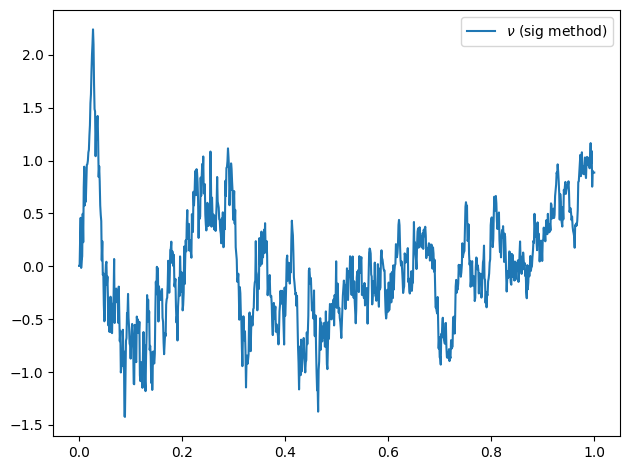

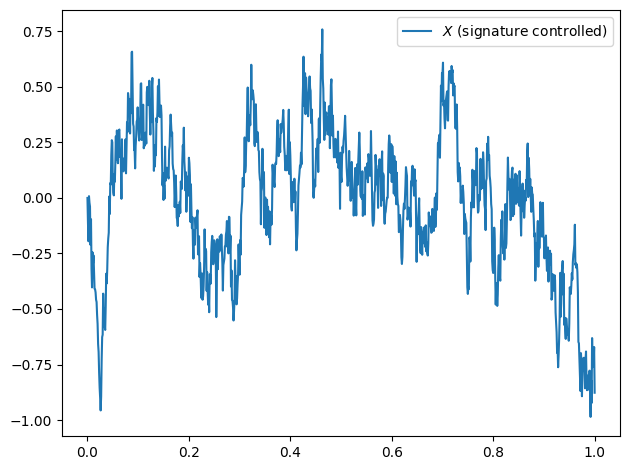

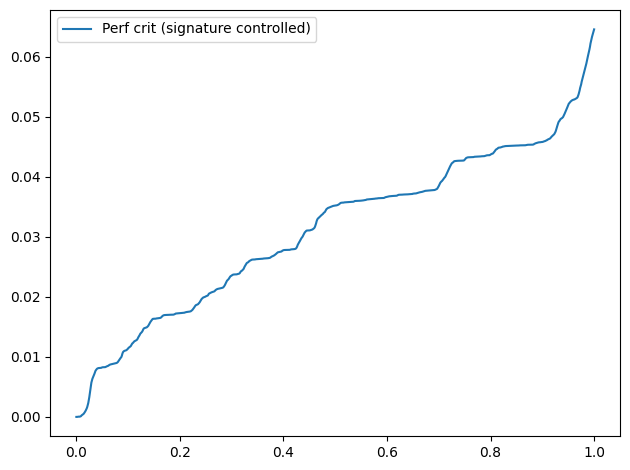

In [22]:
nsim = 0

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$ (sig method)')
#plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)')
#plt.plot(env.timesteps, env_hjb_sig.nu[:,nsim], label=r'$\nu$ (HJB sig representation)', linestyle='-.')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

#plt.plot(env.timesteps, env_hjb.X[:,nsim], label=r'$X$ (HJB controlled)')
plt.plot(env.timesteps, env.X[:, nsim], label=r'$X$ (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

#plt.plot(env.timesteps[:], env_hjb.run_crit[:,nsim], label=r'Perf crit (HJB controlled)')
plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 0.1804259896198762
